# 03 - Figures of the paper

**Question.** Reproduce Figures 1–5 of the BNC2 manuscript from the pipeline outputs.

**Before running.** `python scripts/main.py --rasters` must have produced `output/` and `data_source/summary/`.

**Exports.** `output/figures/figure{1..5}.png` and `.pdf`.

Method changes since the manuscript draft (MYCHOICES C12, C17): three Pan biomes (tropical includes subtropical), FRA accounting units, GSCC draws from BCW (mean 559.6 US$2015/tCO2).

In [7]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SUMMARY, OUTPUT = ROOT / "data_source" / "summary", ROOT / "output"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
CO2_PER_C = 44 / 12

gcw = pd.read_csv(OUTPUT / "country_level_gcw.csv")
ncw = pd.read_csv(OUTPUT / "country_level_ncw.csv")
territories = pd.read_csv(SUMMARY / "territories.csv")
areas = pd.read_csv(SUMMARY / "forest_areas.csv")
by_continent = pd.read_csv(OUTPUT / "tables" / "table2_by_continent.csv")
by_group = pd.read_csv(OUTPUT / "tables" / "table3_by_group.csv")

# Land polygons (Natural Earth) keyed on the FRA accounting units.
NE_TO_UNIT = {"SDS": "SSD", "SAH": "ESH", "PSX": "PSE", "HKG": "CHN", "MAC": "CHN", "TWN": "CHN", "CYN": "CYP",
              "SOL": "SOM", "ALD": "FIN", "ATC": "AUS", "IOA": "AUS"}
world = gpd.read_file("/vsizip/" + (ROOT / "data_source/raw/boundaries/ne_50m_admin_0_countries.zip").as_posix()
                      + "/ne_50m_admin_0_countries.shp")
world["iso3"] = world["ADM0_A3"].replace(NE_TO_UNIT)
world = world.dissolve("iso3", as_index=False)[["iso3", "geometry"]]
world = world.loc[world["iso3"] != "ATA"].to_crs("+proj=robin")

GREENS = ["#e5f5e0", "#c7e9c0", "#a1d99b", "#74c476", "#31a354", "#006d2c", "#00441b"]
GROUP_COLORS = {"Developing economies": "#4c72b0", "SIDS": "#dd8452", "LDCs": "#c44e52", "Developed economies": "#55a868"}


plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Segoe UI Emoji", "DejaVu Sans"],  # DejaVu = secours sur Codespaces (Linux)
    "axes.titlesize": 12, "axes.labelsize": 10, "legend.fontsize": 8,
})

def panel_label(ax, letter, title, subtitle="", x=0.0):
    """Lettre de panneau en gras + titre aligné à gauche."""
    ax.set_title(f"{title}\n{subtitle}" if subtitle else title, loc="left", x=x + 0.045)
    ax.text(x, 1.0, f"({letter})", transform=ax.transAxes, fontweight="bold", fontsize=13, va="bottom")

def choropleth(ax, values, bins, labels, colors, title, subtitle=""):
    """Classed world map: `values` is a Series indexed by iso3, `bins` are the class edges."""
    data = world.merge(values.rename("value"), left_on="iso3", right_index=True, how="left")
    data["cls"] = pd.cut(data["value"], bins=bins, labels=labels)
    data.plot(ax=ax, color="#d9d9d9", linewidth=0.1, edgecolor="white")
    for label, color in zip(labels, colors):
        subset = data.loc[data["cls"] == label]
        if not subset.empty:
            subset.plot(ax=ax, color=color, linewidth=0.1, edgecolor="white")
    handles = [Patch(color=c, label=l) for l, c in zip(labels, colors)] + [Patch(color="#d9d9d9", label="No data")]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False, fontsize=8)
    ax.set_title(f"{title}\n{subtitle}" if subtitle else title, fontsize=11)
    ax.set_axis_off()


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300, bbox_inches="tight")

## Figure 1 - Distribution of forest area

(a) forest area by country, (b) top 5 countries and rest of the world, (c) net annual change in forest area by region. Source: FRA 2025.

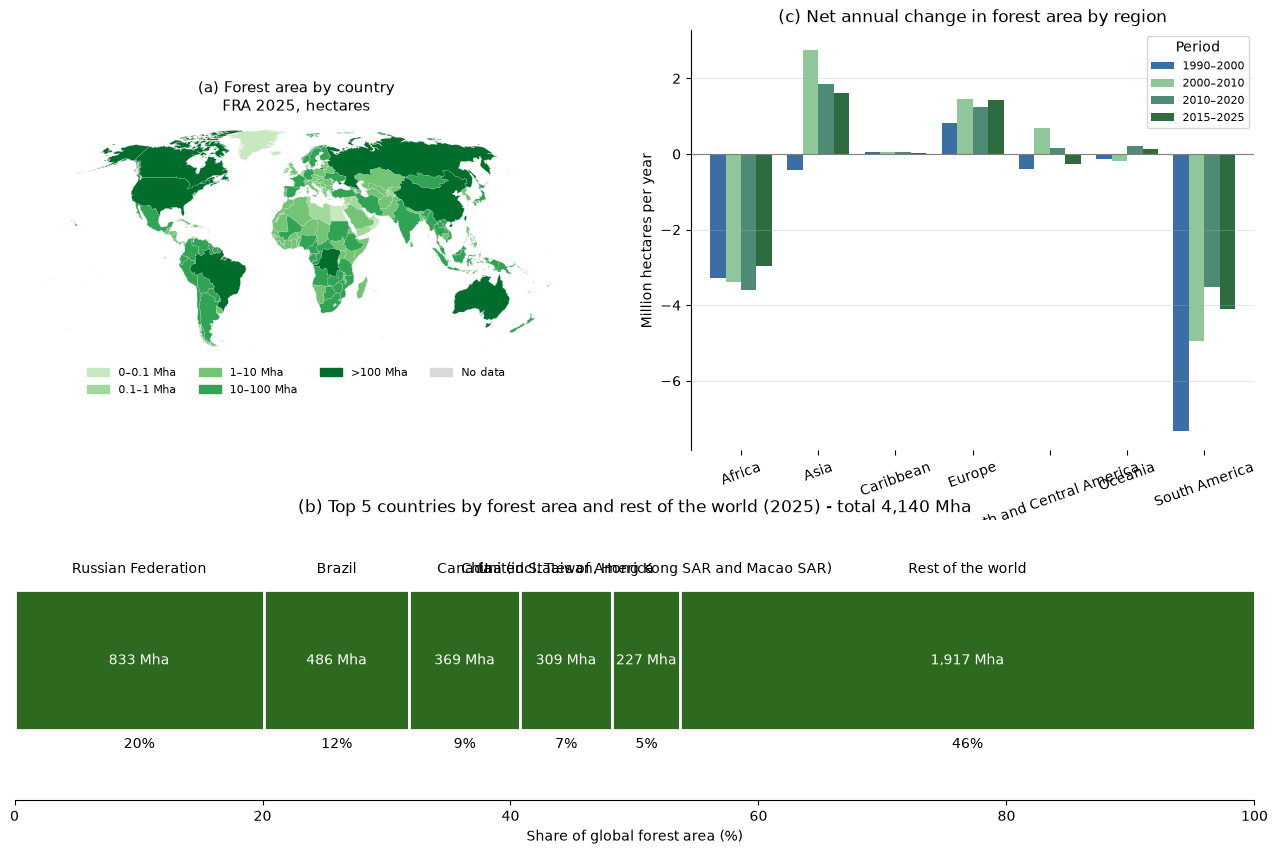

In [6]:
forest_2025 = areas.loc[areas["year"] == 2025].set_index("iso3")["forest"]
fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.5, 1])

ax = fig.add_subplot(grid[0, 0])
choropleth(ax, forest_2025, [-1, 1e5, 1e6, 1e7, 1e8, np.inf],
           ["0–0.1 Mha", "0.1–1 Mha", "1–10 Mha", "10–100 Mha", ">100 Mha"], GREENS[1::1][:5],
           "(a) Forest area by country", "FRA 2025, hectares")

# (c) net annual change by region and period
region = territories.set_index("iso3").apply(
    lambda r: "Caribbean" if r["fra_subregion"] == "Caribbean" else r["fra_region"], axis=1)
wide = areas.pivot(index="iso3", columns="year", values="forest")
periods = {"1990–2000": (1990, 2000), "2000–2010": (2000, 2010), "2010–2020": (2010, 2020), "2015–2025": (2015, 2025)}
change = pd.DataFrame({p: (wide[b] - wide[a]) / (b - a) for p, (a, b) in periods.items()})
change = change.groupby(region.reindex(change.index)).sum() / 1e6
ax = fig.add_subplot(grid[0, 1])
change.plot.bar(ax=ax, color=["#3a6ea5", "#8fc79a", "#4f8a74", "#2e6b3f"], width=0.8)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_ylabel("Million hectares per year")
ax.set_xlabel("")
ax.set_title("(c) Net annual change in forest area by region")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Period", fontsize=8)
ax.grid(axis="y", alpha=.3)
for sp in ["top", "bottom", "right"]:
    ax.spines[sp].set_visible(False)

# (b) top 5 + rest of the world
ax = fig.add_subplot(grid[1, :])
names = territories.set_index("iso3")["name"]
top = forest_2025.sort_values(ascending=False)
parts = pd.concat([top.head(5), pd.Series({"Rest of the world": top.iloc[5:].sum()})]) / 1e6
share, left = 100 * parts / parts.sum(), 0.0
for key, value in parts.items():
    width = share[key]
    ax.barh(0, width, left=left, color="#2d6a1f", edgecolor="white", linewidth=2)
    ax.text(left + width / 2, 0, f"{value:,.0f} Mha", ha="center", va="center", color="white")
    ax.text(left + width / 2, 0.5, names.get(key, key), ha="center")
    ax.text(left + width / 2, -0.5, f"{width:.0f}%", ha="center")
    left += width
ax.set_xlim(0, 100)
ax.set_ylim(-0.8, 0.8)
ax.set_yticks([])
ax.set_xlabel("Share of global forest area (%)")
ax.set_title(f"(b) Top 5 countries by forest area and rest of the world (2025) - total {parts.sum():,.0f} Mha")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
save(fig, "figure1")

TypeError: choropleth() takes from 6 to 7 positional arguments but 8 were given

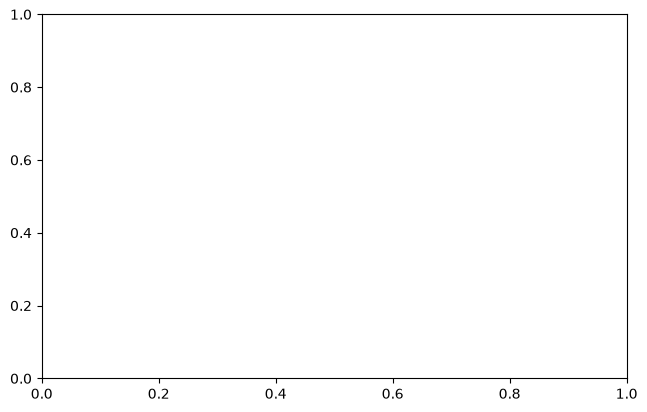

In [8]:
import textwrap

forest_2025 = areas.loc[areas["year"] == 2025].set_index("iso3")["forest"]
fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], width_ratios=[1, 1], hspace=0.35, wspace=0.12)

# (a) carte
ax_map = fig.add_subplot(grid[0, 0])
choropleth(ax_map, forest_2025, [-1, 1e5, 1e6, 1e7, 1e8, np.inf],
           ["0–0.1 Mha", "0.1–1 Mha", "1–10 Mha", "10–100 Mha", ">100 Mha"], GREENS[1:6],
           "a", "Forest area by country", "FRA 2025")

# (b) variation annuelle nette par région (ex-(c))
region = territories.set_index("iso3").apply(
    lambda r: "Caribbean" if r["fra_subregion"] == "Caribbean" else r["fra_region"], axis=1)
wide = areas.pivot(index="iso3", columns="year", values="forest")
periods = {"1990–2000": (1990, 2000), "2000–2010": (2000, 2010),
           "2010–2020": (2010, 2020), "2015–2025": (2015, 2025)}
change = pd.DataFrame({p: (wide[b] - wide[a]) / (b - a) for p, (a, b) in periods.items()})
change = (change.groupby(region.reindex(change.index)).sum() / 1e6).sort_index()

ax = fig.add_subplot(grid[0, 1])
change.plot.bar(ax=ax, color=["#3a6ea5", "#8fc79a", "#4f8a74", "#2e6b3f"], width=0.8, legend=False)
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_ylabel("Million hectares per year")
ax.set_xlabel("")
ax.set_xticks([])                                   # supprime les ticks orphelins
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.legend(title="Period", frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
panel_label(ax, "b", "Net annual change in forest area by region")

# nom du continent sous son groupe de barres, avec une ligne de rappel
bottom = change.min().min() * 1.05
for position, name in enumerate(change.index):
    ax.plot([position, position], [bottom, bottom * 0.94], color="#999999", linewidth=0.8, clip_on=False)
    ax.annotate(textwrap.fill(name, 12), (position, bottom * 1.02),
                ha="center", va="top", fontsize=9, annotation_clip=False)
ax.set_ylim(bottom * 1.22, change.max().max() * 1.45)

# (c) top 5 + reste du monde, en codes ISO (ex-(b))
ax = fig.add_subplot(grid[1, :])
top = forest_2025.sort_values(ascending=False)
parts = pd.concat([top.head(5), pd.Series({"Rest of the world": top.iloc[5:].sum()})]) / 1e6
share, left = 100 * parts / parts.sum(), 0.0
for key, value in parts.items():
    width = share[key]
    ax.barh(0, width, left=left, color="#2d6a1f", edgecolor="white", linewidth=2)
    ax.text(left + width / 2, 0, f"{value:,.0f} Mha", ha="center", va="center", color="white", fontsize=11)
    ax.text(left + width / 2, 0.62, key, ha="center", fontsize=11,
            fontweight="bold" if key != "Rest of the world" else "normal")
    ax.text(left + width / 2, -0.62, f"{width:.0f}%", ha="center", fontsize=10)
    left += width
ax.set_xlim(0, 100)
ax.set_ylim(-1.0, 1.0)
ax.set_yticks([]); ax.set_xticks([])                # axe du bas supprimé, voir ci-dessous
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
panel_label(ax, "c", f"Top 5 countries by forest area and rest of the world (2025) — global total {parts.sum():,.0f} Mha")

fig.text(0.5, 0.02, "* CHN includes Taiwan, Hong Kong SAR and Macao SAR, as in FAO statistics (MYCHOICES C12).",
         ha="center", fontsize=8)
save(fig, "figure1")

## Figure 2 - Forest carbon uptake

(a) national uptake, (b) contribution of the three Pan biomes, (c) uptake by development group. Route B, mangroves excluded.

In [ ]:
uptake_mtc = gcw.set_index("iso3")["uptake_tco2_yr_mean"] / CO2_PER_C / 1e6

biome_area = pd.read_csv(SUMMARY / "forest_area_by_biome.csv").query("variant == 'excl_mangroves'")
rates = pd.read_csv(SUMMARY / "biome_rates.csv").set_index("pan_biome")["rate_tc_ha_yr_mean"]
biome_mtc = (biome_area.groupby("pan_biome")["area_ha"].sum() * rates / 1e6).sort_values(ascending=False)

fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])
ax = fig.add_subplot(grid[0, :])
choropleth(ax, uptake_mtc, [-np.inf, 5, 20, 50, 100, np.inf], ["0–5", "5–20", "20–50", "50–100", ">100"], GREENS[1:6],
           "(a) Spatial distribution of national forest carbon uptake", "MtC per year")

ax = fig.add_subplot(grid[1, 0])
x = 0.0
for (biome, value), color in zip(biome_mtc.items(), ["#5e9a6e", "#7fbc8c", "#dbeed9"]):
    radius = np.sqrt(value / biome_mtc.max())
    x += radius
    ax.add_patch(plt.Circle((x, 0), radius, color=color))
    ax.text(x, 0, f"{value:,.0f}\nMtC yr⁻¹", ha="center", va="center")
    ax.text(x, -radius - 0.12, biome.capitalize(), ha="center")
    x += radius + 0.1
ax.set_xlim(-0.1, x)
ax.set_ylim(-1.3, 1.1)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("(b) Biome contribution to global forest carbon uptake")

ax = fig.add_subplot(grid[1, 1])
groups = uptake_mtc.groupby(gcw.set_index("iso3")["groups"]).sum().sort_values()
groups.plot.barh(ax=ax, color=[GROUP_COLORS.get(g, "grey") for g in groups.index], edgecolor="black")
ax.set_xlabel("Forest carbon uptake (MtC yr⁻¹)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_title("(c) Forest carbon uptake by development group")
save(fig, "figure2")

## Figure 3 - Green Carbon Wealth

(a) GCW per capita, (b) GCW/GDP for the top 30 countries, (c) total GCW, (d) GCW per capita for the top 30 countries.

In [ ]:
g = gcw.set_index("iso3")
fig, axes = plt.subplots(2, 2, figsize=(18, 11), gridspec_kw={"width_ratios": [1.2, 1]})

choropleth(axes[0, 0], g["gcw_per_capita_usd2015"], [-np.inf, 1e3, 5e3, 1e4, 2.5e4, 5e4, 1e5, np.inf],
           ["<1,000 $", "1,000–5,000 $", "5,000–10,000 $", "10,000–25,000 $", "25,000–50,000 $", "50,000–100,000 $", ">100,000 $"],
           GREENS, "(a) Mapping Green Carbon Wealth of nations", "GCW per capita (US$2015/yr)")
choropleth(axes[1, 0], g["gcw_usd2015_yr_mean"] / 1e9, [-np.inf, 10, 50, 100, 250, 500, 1000, np.inf],
           ["<10 B$", "10–50 B$", "50–100 B$", "100–250 B$", "250–500 B$", "500–1000 B$", ">1000 B$"],
           GREENS, "(c) Mapping Green Carbon Wealth by country", "Total GCW (billion US$2015/yr)")


def top30(ax, column, title, ylabel, log=False):
    top = g[column].dropna().sort_values(ascending=False).head(30)
    ax.bar(top.index, top, color=[GROUP_COLORS.get(x, "grey") for x in g.loc[top.index, "groups"]])
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=90)
    if log:
        ax.set_yscale("log")
    present = g.loc[top.index, "groups"].dropna().unique()
    ax.legend(handles=[Patch(color=GROUP_COLORS[k], label=k) for k in present if k in GROUP_COLORS], title="Groups", fontsize=8)


top30(axes[0, 1], "gcw_share_of_gdp", "(b) GCW relative to GDP, top 30 countries", "GCW / GDP")
top30(axes[1, 1], "gcw_per_capita_usd2015", "(d) GCW per capita, top 30 countries", "GCW per capita (US$2015)", log=True)
save(fig, "figure3")

## Figure 4 - Natural Carbon Wealth decomposition: GCW vs BCW

By continent and by country group, from `table2_by_continent.csv` and `table3_by_group.csv`.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, table, key, title in [(axes[0], by_continent, "continent", "By continent"), (axes[1], by_group, "groups", "By country group")]:
    data = table.loc[table[key] != "Unclassified"].set_index(key).sort_values("ncw_usd2015_yr_mean")
    green, blue = data["gcw_usd2015_yr_mean"] / 1e9, data["bcw_usd2015_yr_mean"] / 1e9
    ax.barh(data.index, green, color="#2e8b57", label="Green Carbon Wealth")
    ax.barh(data.index, blue, left=green, color="#006994", label="Blue Carbon Wealth")
    for y, (gv, bv) in enumerate(zip(green, blue)):
        total = gv + bv
        ax.text(total * 1.01, y, f"{100 * gv / total:.0f}% | {100 * bv / total:.0f}%", va="center", fontsize=9)
    ax.set_xlabel("NCW (billion US$2015/yr)")
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")
fig.suptitle("NCW decomposition: GCW vs BCW (shares: green | blue)", fontsize=15, fontweight="bold")
save(fig, "figure4")

## Figure 5 - Global distribution of Natural Carbon Wealth

(a) total NCW, (b) NCW per capita.

In [ ]:
n = ncw.set_index("iso3")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
choropleth(axes[0], n["ncw_usd2015_yr_mean"] / 1e9, [-np.inf, 1, 10, 50, 200, np.inf], ["<1 B$", "1–10 B$", "10–50 B$", "50–200 B$", ">200 B$"],
           GREENS[1:6], "(a) Global NCW distribution", "Total NCW (billion US$2015/yr)")
choropleth(axes[1], n["ncw_per_capita_usd2015"], [-np.inf, 100, 500, 2e3, 1e4, np.inf], ["<100 $", "100–500 $", "500–2k $", "2k–10k $", ">10k $"],
           ["#fee0d2", "#fcbba1", "#fc9272", "#de2d26", "#a50f15"], "(b) Per capita normalisation reshapes global NCW distribution",
           "NCW per capita (US$2015/yr)")
save(fig, "figure5")